# Customer Churn Prediction: Complete ML Pipeline

**Workflow**

1. Import libraries
2. Load the data
3. Inspect the data
4. Clean the data
5. Exploratory data analysis (EDA)
6. Split into train and test sets
7. Build the preprocessing step
8. Train and tune three models (cross-validation)
9. Select the best model (using cross-validation, not the test set)
10. Evaluate once on the test set
11. Interpret the model
12. Save one pipeline file for the app
13. Test the saved file the way the app will use it

**Why a Pipeline?** Scaling and encoding live *inside* the saved model, so the Streamlit app only passes raw customer values. Scaler and model can never get out of sync.

## Step 1: Import libraries

In [1]:
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.7.2


## Step 2: Load the data
The CSV must be in the same folder as this notebook.

In [3]:
df = pd.read_csv("Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 3: Inspect the data

In [4]:
df.info()
print()
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print()
print(df["Churn"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**Notice:** `TotalCharges` has type `object` (text) even though it should be a number. Some rows contain blank spaces. We fix this in Step 4.

## Step 4: Clean the data

In [5]:
# 1) customerID is only an identifier, it has no predictive value
df = df.drop(columns=["customerID"])

# 2) TotalCharges: text -> number
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank = df["TotalCharges"].isnull()
print("Blank TotalCharges rows:", blank.sum())
print("Their tenure values:", df.loc[blank, "tenure"].unique())   # all 0 = brand-new customers

# New customers have not been billed yet, so 0 is the correct fill value
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# 3) Target column: No -> 0, Yes -> 1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# 4) Remove exact duplicate rows (so the same row cannot land in both train and test)
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", before - len(df))

print("Remaining missing values:", df.isnull().sum().sum())
print("Final shape:", df.shape)

Blank TotalCharges rows: 11
Their tenure values: [0]
Duplicates removed: 22
Remaining missing values: 0
Final shape: (7021, 20)


## Step 5: Exploratory data analysis (EDA)

Churn
0    73.6
1    26.4
Name: proportion, dtype: float64


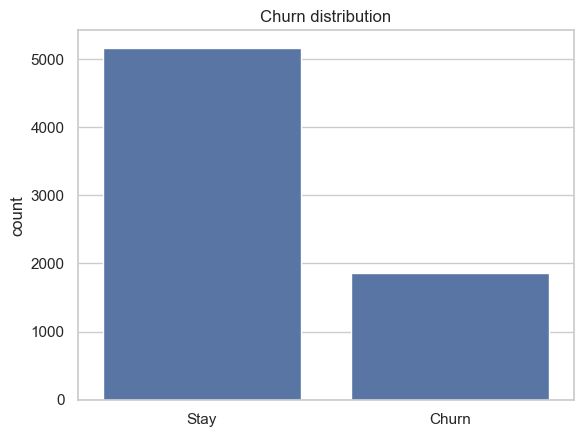

In [6]:
# Target balance
print(df["Churn"].value_counts(normalize=True).mul(100).round(1))
sns.countplot(x=df["Churn"].map({0: "Stay", 1: "Churn"}))
plt.title("Churn distribution")
plt.xlabel("")
plt.show()

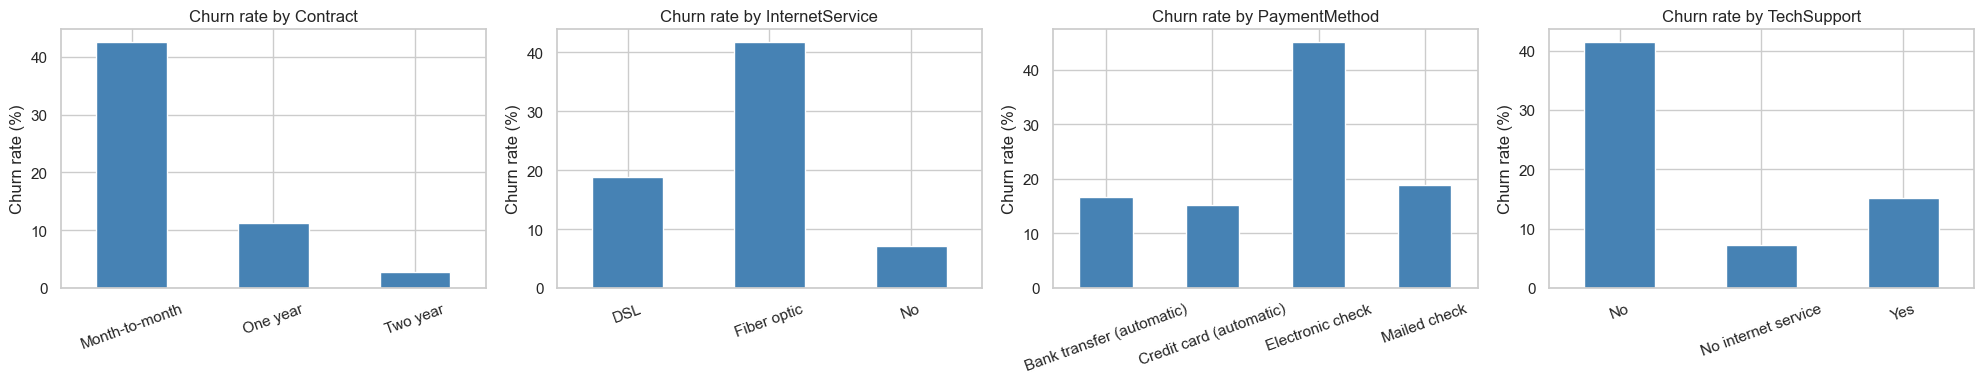

In [7]:
# Churn rate (%) for important categories
cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, cols):
    rate = df.groupby(col)["Churn"].mean().mul(100)
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

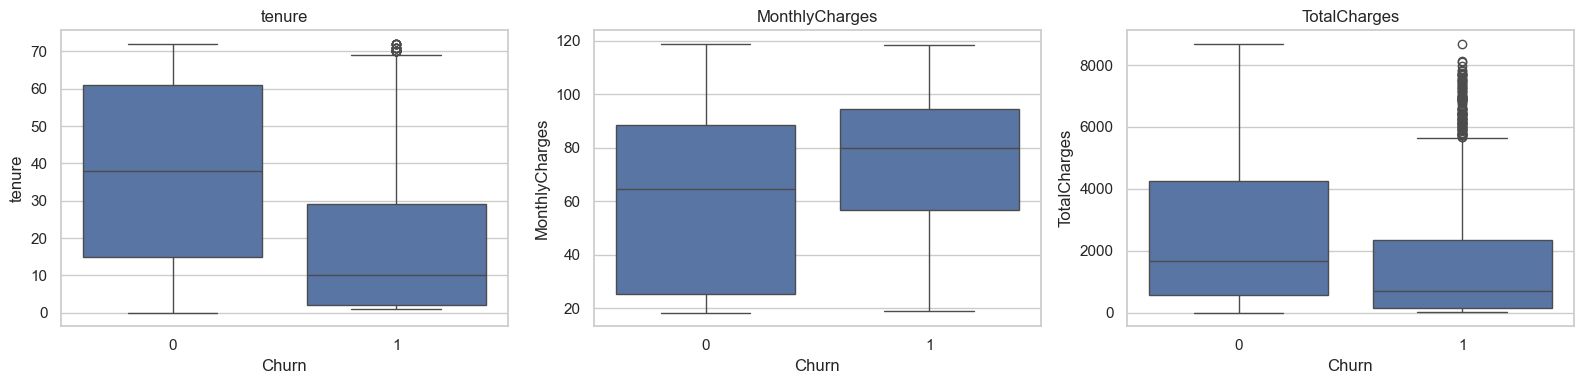

In [8]:
# Numeric columns vs churn
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(x="Churn", y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

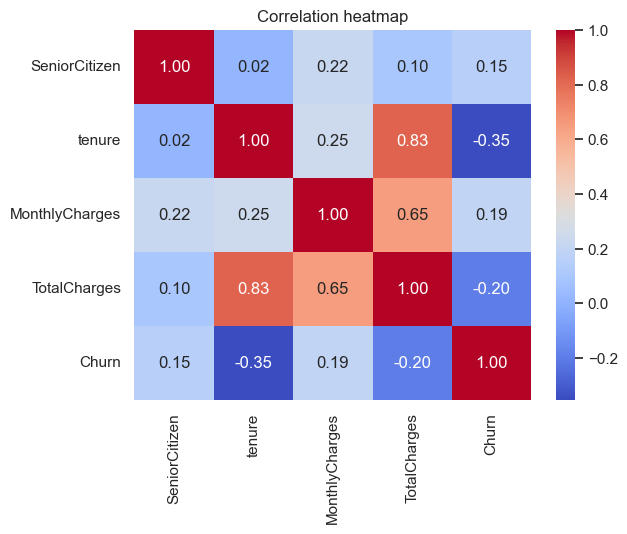

In [9]:
# Correlation of numeric columns (including the target)
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

**What the EDA shows:** month-to-month contracts, fiber optic internet, electronic check payment, no tech support and short tenure all go with higher churn.

## Step 6: Split into train and test sets

We split **before** any fitting. The test set stays untouched until the final evaluation (Step 10).
`stratify=y` keeps the same churn percentage in both sets.

In [10]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean() * 100, 1), "%  test:", round(y_test.mean() * 100, 1), "%")

# Group the columns by type
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]   # need scaling
bin_cols = ["SeniorCitizen"]                              # already 0/1
cat_cols = [c for c in X.columns if c not in num_cols + bin_cols]  # text -> one-hot

print("Categorical columns:", cat_cols)

Train: (5616, 19)  Test: (1405, 19)
Churn rate train: 26.4 %  test: 26.5 %
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Step 7: Build the preprocessing step

- numeric columns -> `StandardScaler`
- `SeniorCitizen` (already 0/1) -> unchanged
- text columns -> `OneHotEncoder` (`handle_unknown="ignore"` prevents crashes on unseen categories)

The scaler and encoder learn from the training data only, inside each cross-validation fold, so there is no data leakage.

In [12]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("bin", "passthrough", bin_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
preprocess

,transformers,"[('num', ...), ('bin', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,copy,True
,with_mean,True
,with_std,True


## Step 8: Train and tune three models

Each model is wrapped in a Pipeline (`preprocess` -> `model`). `GridSearchCV` tries a small grid of settings using 5-fold stratified cross-validation on the **training set only**, scored with ROC-AUC.

`class_weight="balanced"` is used because only about 27% of customers churn.

In [13]:
model_grid = {
    "Logistic Regression": (
        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
        {"model__C": [0.01, 0.1, 1, 10]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"model__max_depth": [3, 5, 7], "model__min_samples_leaf": [10, 30]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE),
        {"model__max_depth": [6, 8, 12], "model__min_samples_leaf": [5, 10]},
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
searches = {}

for name, (estimator, grid) in model_grid.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", estimator)])
    search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=1)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name:20s} CV ROC-AUC = {search.best_score_:.4f}   best settings: {search.best_params_}")

Logistic Regression  CV ROC-AUC = 0.8460   best settings: {'model__C': 10}
Decision Tree        CV ROC-AUC = 0.8329   best settings: {'model__max_depth': 5, 'model__min_samples_leaf': 30}
Random Forest        CV ROC-AUC = 0.8482   best settings: {'model__max_depth': 8, 'model__min_samples_leaf': 5}


## Step 9: Select the best model

We choose using the **cross-validation score** (training data only). Choosing by test score would make the final test result too optimistic.

In [14]:
cv_table = pd.DataFrame({
    "Model": list(searches.keys()),
    "CV ROC-AUC": [s.best_score_ for s in searches.values()],
}).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)

best_name = cv_table.loc[0, "Model"]
print("Best model:", best_name)
cv_table.round(4)

Best model: Random Forest


,Model,CV ROC-AUC
0,Random Forest,0.8482
1,Logistic Regression,0.8460
2,Decision Tree,0.8329


## Step 10: Evaluate on the test set (only once)

Metrics use the default threshold of 0.5.
- **Precision:** of customers flagged as churners, how many really churned
- **Recall:** of customers who really churned, how many we caught

In [15]:
rows, probs = [], {}
for name, search in searches.items():
    p = search.best_estimator_.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probs[name] = p
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, p),
    })

test_results = pd.DataFrame(rows).round(3)
test_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.739,0.504,0.782,0.613,0.840
1,Decision Tree,0.742,0.509,0.753,0.607,0.827
2,Random Forest,0.764,0.539,0.763,0.632,0.842


Selected model: Random Forest
              precision    recall  f1-score   support

        Stay       0.90      0.76      0.83      1033
       Churn       0.54      0.76      0.63       372

    accuracy                           0.76      1405
   macro avg       0.72      0.76      0.73      1405
weighted avg       0.80      0.76      0.78      1405



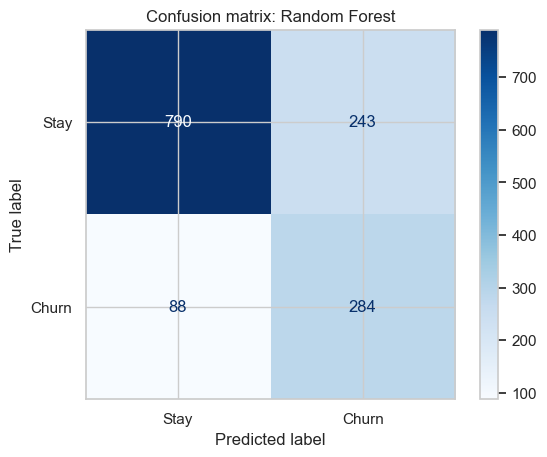

In [16]:
# Detailed report for the selected model
best_probs = probs[best_name]
best_pred = (best_probs >= 0.5).astype(int)

print("Selected model:", best_name)
print(classification_report(y_test, best_pred, target_names=["Stay", "Churn"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred),
                       display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title(f"Confusion matrix: {best_name}")
plt.show()

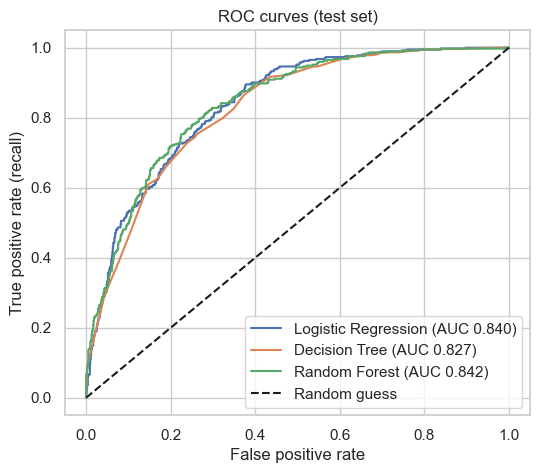

In [17]:
# ROC curves for all models
plt.figure(figsize=(6, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves (test set)")
plt.legend()
plt.show()

In [18]:
# How the threshold changes the trade-off (the app lets the user move this)
thr_rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (best_probs >= t).astype(int)
    thr_rows.append({"Threshold": t,
                     "Precision": precision_score(y_test, pred),
                     "Recall": recall_score(y_test, pred),
                     "Customers flagged": int(pred.sum())})
pd.DataFrame(thr_rows).round(3)

,Threshold,Precision,Recall,Customers flagged
0,0.3,0.428,0.909,789
1,0.4,0.477,0.841,656
2,0.5,0.539,0.763,527
3,0.6,0.600,0.661,410
4,0.7,0.642,0.505,293


## Step 11: Interpret the model

Which features matter most? (Importance shows what the model uses, not what causes churn.)

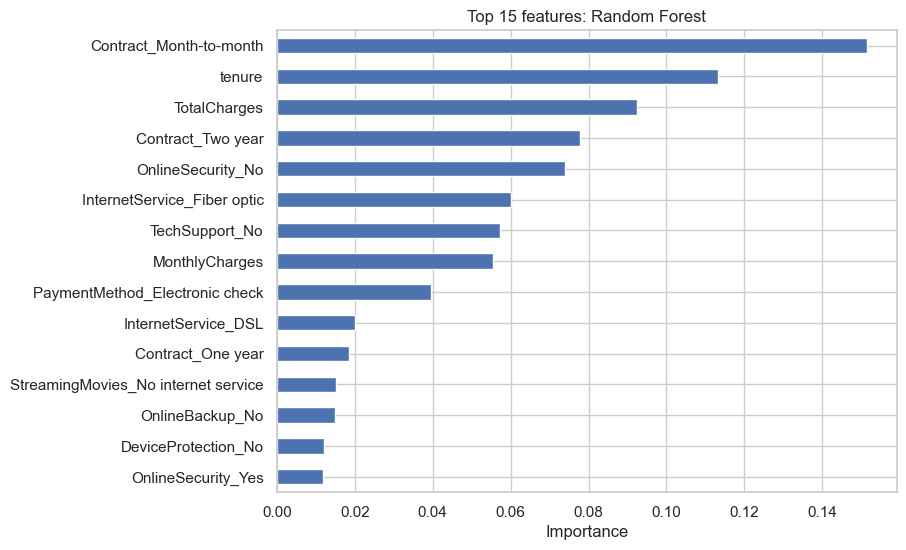

In [19]:
final_pipeline = searches[best_name].best_estimator_

names = final_pipeline.named_steps["preprocess"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]          # remove the "num__" / "cat__" prefix
fitted_model = final_pipeline.named_steps["model"]

if hasattr(fitted_model, "feature_importances_"):
    values, label = fitted_model.feature_importances_, "Importance"
else:
    values, label = fitted_model.coef_[0], "Coefficient (+ raises churn risk, - lowers it)"

imp = pd.Series(values, index=names)
top = imp.reindex(imp.abs().sort_values(ascending=False).head(15).index).iloc[::-1]

top.plot(kind="barh", figsize=(8, 6), title=f"Top 15 features: {best_name}")
plt.xlabel(label)
plt.show()

## Step 12: Save the final pipeline

One file contains scaler, encoder and model. A small JSON file stores the metrics for the dashboard.

In [20]:
joblib.dump(final_pipeline, "churn_pipeline.pkl")

best_row = test_results[test_results["Model"] == best_name].iloc[0]
metrics = {
    "model_name": best_name,
    "sklearn_version": sklearn.__version__,
    "cv_roc_auc": float(cv_table.loc[0, "CV ROC-AUC"]),
    "test_accuracy": float(best_row["Accuracy"]),
    "test_precision": float(best_row["Precision"]),
    "test_recall": float(best_row["Recall"]),
    "test_f1": float(best_row["F1"]),
    "test_roc_auc": float(best_row["ROC-AUC"]),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
}
with open("model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

import os
print("Saved in:", os.getcwd())
print([f for f in os.listdir() if f.endswith((".pkl", ".json"))])

Saved in: C:\Users\SAMSUNG\Desktop\Customer_Churn_Intelligence
['churn_pipeline.pkl', 'model_metrics.json']


## Step 13: Test the saved file the way the app will use it

Load the pipeline from disk and predict from **raw** values (no manual scaling or encoding).

In [21]:
loaded = joblib.load("churn_pipeline.pkl")

# 1) The loaded pipeline must give the same results as the one in memory
assert np.allclose(loaded.predict_proba(X_test)[:, 1], final_pipeline.predict_proba(X_test)[:, 1])
print("Loaded pipeline matches the trained pipeline.")

# 2) One new customer, exactly like the app builds it
new_customer = pd.DataFrame([{
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
    "tenure": 3, "PhoneService": "Yes", "MultipleLines": "No",
    "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No", "StreamingMovies": "No",
    "Contract": "Month-to-month", "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.0, "TotalCharges": 255.0,
}])
print("Churn probability:", round(float(loaded.predict_proba(new_customer)[0, 1]) * 100, 1), "%")

Loaded pipeline matches the trained pipeline.
Churn probability: 85.2 %


## Done

Files created next to this notebook:

| File | Purpose |
|---|---|
| `churn_pipeline.pkl` | preprocessing and model in one file |
| `model_metrics.json` | metrics shown in the dashboard |

Keep `app.py` and `Telco-Customer-Churn.csv` in the same folder, then run the app.